# Experiments

In [2]:
from utils import generate_random_normal, generate_plot

## Marchenko Pastur

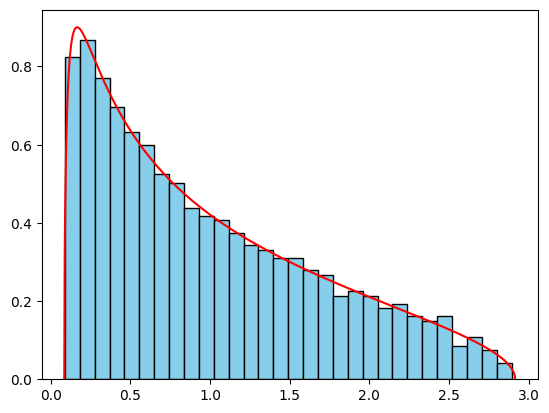

---


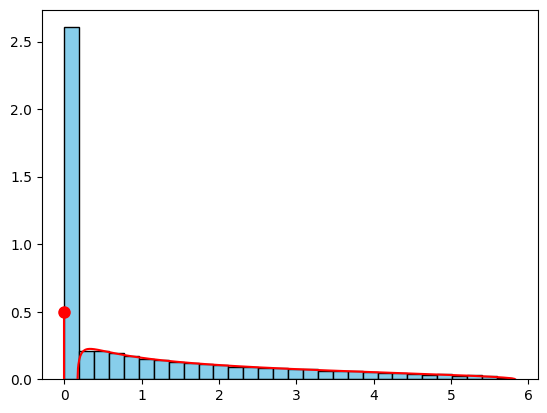

In [3]:
matrix1 = generate_random_normal(1000, 2000)
matrix2 = generate_random_normal(2000, 1000)

generate_plot(matrix1)
print("---")
generate_plot(matrix2)

## Neural Network

### Dense Layer

In [5]:
class DenseLayer:
    def __init__(self, input_dim, output_dim):
        self.weights = np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)
        self.biases = np.zeros((1, output_dim))
        
        self.input = None
        self.dweights = None
        self.dbiases = None

    def forward(self, input_data):
        self.input = input_data
        
        return np.dot(self.input, self.weights) + self.biases

    def backward(self, output_gradient, learning_rate):
        self.dweights = np.dot(self.input.T, output_gradient)
        self.dbiases = np.sum(output_gradient, axis=0, keepdims=True)
        
        input_gradient = np.dot(output_gradient, self.weights.T)
        
        self.weights -= learning_rate * self.dweights
        self.biases -= learning_rate * self.dbiases
        
        return input_gradient

### Activation Layer

In [6]:
class ReLUActivation:
    def __init__(self):
        self.input = None

    def forward(self, input_data):
        self.input = input_data
        return np.maximum(0, input_data)

    def backward(self, output_gradient, learning_rate):
        return output_gradient * (self.input > 0)

### Neural Network Class

In [7]:
class NeuralNetwork:
    def __init__(self):
        self.layers = []

    def add(self, layer):
        self.layers.append(layer)

    def forward(self, x):
        output = x
        for layer in self.layers:
            output = layer.forward(output)
            
        return output

    def backward(self, loss_gradient, learning_rate):
        grad = loss_gradient
        
        for layer in reversed(self.layers):
            grad = layer.backward(grad, learning_rate)
            
    def fit(self, X, y, epochs, learning_rate):
        for epoch in range(epochs):
            predictions = self.forward(X)
            
            loss = np.mean((predictions - y) ** 2)
            loss_grad = 2 * (predictions - y) / X.shape[0] 
            
            self.backward(loss_grad, learning_rate)
            
            if (epoch + 1) % 100 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.6f}")

### Testing

In [8]:
np.random.seed(42)
X_train = np.random.randn(100, 2)
y_train = (X_train[:, 0:1] * 2) + (X_train[:, 1:2] ** 2)  

nn = NeuralNetwork()

nn.add(DenseLayer(input_dim=2, output_dim=4))
nn.add(ReLUActivation())
nn.add(DenseLayer(input_dim=4, output_dim=1))

nn.fit(X_train, y_train, epochs=500, learning_rate=0.1)

Epoch 1/500 - Loss: 3.703165
Epoch 100/500 - Loss: 0.251397
Epoch 200/500 - Loss: 0.142692
Epoch 300/500 - Loss: 0.214269
Epoch 400/500 - Loss: 0.150972
Epoch 500/500 - Loss: 0.125684
